In [22]:
import os
import sys
import requests
import datetime as dt
import numpy as np
from dotenv import load_dotenv
from pathlib import Path
import requests
import pandas as pd
import talib as ta
import plotly.graph_objs as go

import ipywidgets as widgets
from ipywidgets import Dropdown, Text, Button, Output
from IPython.display import display

from Modules.utility import Utility
from Modules.show_plot import ShowPlot
from Modules.reques_api import RequestApi
from Modules.get_market_data import GetMarketData
from Modules.stock_prices_and_market_data import ClassStockPricesMarketData
from Modules.financial import Financial
from Modules.pdf_url_to_markdown import PDFUrlToMarkdown
from Modules.webpage_to_markdown import WebpageToMarkdown
from Modules.compute_fibonacci_extension import ComputeFibonacciExtension

In [23]:
API_BASE_URL = os.getenv("API_BASE_URL", "http://localhost:8000")
request_api = RequestApi(API_BASE_URL)
get_market_data = GetMarketData(Path('/workspace/data'))
utility = Utility()
stock_prices_market_data = ClassStockPricesMarketData()
financial = Financial()
# URLからPDFをダウンロードしてMarkdownに変換するクラスのインスタンスを作成
pdf_to_md = PDFUrlToMarkdown()
# WEBページをMarkdownに変換する関数
webpage_to_markdown = WebpageToMarkdown()
# Fibonacciエクステンションを計算するクラスのインスタンスを作成
fibonacci_extension = ComputeFibonacciExtension()

### WTIの時系列データを取得

In [24]:
wti = 'CL=F'
start = '1999-01-01'
end = dt.datetime.now().strftime('%Y-%m-%d')
response = request_api.update_commodity_timeseries_data(
    code=wti,
    market=None,
    start=start,
    end=end
)
response

{'result': True}

In [25]:
wti_df = request_api.get_commodity_time_series_data(
    code=wti,
    market=None,
    start=start,
    end=end
)
wti_df.head()

取得件数: 6557


,id,commodity_id,commodity_code,commodity_market,date,open,high,low,close,adj_close,...,rci26,rci52,cross,gc,dc,macd_gc,macd_dc,rci_gc,rci_dc,rising_condition
0,6530,2,CL=F,None,2000-08-23,32.049999,32.799999,31.950001,31.950001,None,...,NaN,NaN,False,NaN,NaN,NaN,NaN,NaN,NaN,False
1,6531,2,CL=F,None,2000-08-24,31.629999,32.240002,31.400000,31.900000,None,...,NaN,NaN,False,NaN,NaN,NaN,NaN,NaN,NaN,False
2,6532,2,CL=F,None,2000-08-25,32.049999,32.099998,31.320000,31.700001,None,...,NaN,NaN,False,NaN,NaN,NaN,NaN,NaN,NaN,False
3,6533,2,CL=F,None,2000-08-28,32.869999,32.919998,31.860001,32.040001,None,...,NaN,NaN,False,NaN,NaN,NaN,NaN,NaN,NaN,False
4,6534,2,CL=F,None,2000-08-29,32.720001,33.029999,32.560001,32.820000,None,...,NaN,NaN,False,NaN,NaN,NaN,NaN,NaN,NaN,False


#### S&P500の時系列データを取得

In [26]:
sp500 = '^GSPC'

response = request_api.update_stock_timeseries_data(
    code=sp500,
    market=None,
    start=start,
    end=end
)
response

{'result': True}

In [27]:
sp_timeseries_df = request_api.get_stock_time_series_data(
    code=sp500,
    market=None,
    start=start,
    end=end
)
sp_timeseries_df.head()

取得件数: 7011


,id,stock_code,stock_market,date,open,high,low,close,volume,ma5,...,lower1,rci52,cross,gc,dc,macd_gc,macd_dc,rci_gc,rci_dc,rising_condition
0,1064856,^GSPC,None,1998-11-17,1139.319946,1151.709961,1129.670044,1135.869995,705200000,NaN,...,NaN,NaN,False,NaN,NaN,NaN,NaN,NaN,NaN,False
1,1064857,^GSPC,None,1998-11-18,1144.479980,1144.520020,1133.069946,1139.319946,652510000,NaN,...,NaN,NaN,False,NaN,NaN,NaN,NaN,NaN,NaN,False
2,1064858,^GSPC,None,1998-11-19,1152.609985,1155.099976,1144.420044,1144.479980,671000000,NaN,...,NaN,NaN,False,NaN,NaN,NaN,NaN,NaN,NaN,False
3,1064859,^GSPC,None,1998-11-20,1163.550049,1163.550049,1152.609985,1152.609985,721200000,NaN,...,NaN,NaN,False,NaN,NaN,NaN,NaN,NaN,NaN,False
4,1064860,^GSPC,None,1998-11-23,1188.209961,1188.209961,1163.550049,1163.550049,774100000,1147.165991,...,NaN,NaN,False,NaN,NaN,NaN,NaN,NaN,NaN,False


#### XOMの時系列データを取得

In [28]:
xom = 'XOM'

response = request_api.update_stock_timeseries_data(
    code=xom,
    market=None,
    start=start,
    end=end
)
response

{'result': True}

In [29]:
xom_timeseries_df = request_api.get_stock_time_series_data(
    code=xom,
    market=None,
    start=start,
    end=end
)
xom_timeseries_df

取得件数: 13904


,id,stock_code,stock_market,date,open,high,low,close,volume,ma5,...,lower1,rci52,cross,gc,dc,macd_gc,macd_dc,rci_gc,rci_dc,rising_condition
0,507236,XOM,NYSE,1998-11-17,14.915027,15.311352,14.901816,15.047135,5074400,NaN,...,NaN,NaN,False,NaN,NaN,NaN,NaN,NaN,NaN,False
1,1071850,XOM,NaN,1998-11-17,14.915029,15.311354,14.901818,15.047137,5074400,NaN,...,NaN,NaN,False,NaN,NaN,NaN,NaN,NaN,NaN,False
2,507237,XOM,NYSE,1998-11-18,14.941441,15.007495,14.756489,14.875386,6623200,NaN,...,NaN,NaN,False,NaN,NaN,NaN,NaN,NaN,NaN,False
3,1071851,XOM,NaN,1998-11-18,14.941445,15.007499,14.756494,14.875391,6623200,NaN,...,NaN,NaN,False,NaN,NaN,NaN,NaN,NaN,NaN,False
4,507238,XOM,NYSE,1998-11-19,14.769703,14.994287,14.703649,14.941444,6319600,14.957299,...,NaN,NaN,False,NaN,NaN,NaN,NaN,NaN,NaN,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
13899,1096960,XOM,NaN,2026-09-28,162.520004,163.539993,161.050003,162.800003,12809500,160.647998,...,159.157332,74.728934,False,NaN,NaN,NaN,NaN,NaN,NaN,False
13900,1096961,XOM,NaN,2026-09-29,161.350006,161.970001,159.270004,160.220001,9160000,161.185999,...,159.005832,71.826176,False,NaN,NaN,NaN,NaN,NaN,NaN,False
13901,1096962,XOM,NaN,2026-09-30,162.750000,164.369995,161.800003,162.229996,13100400,161.707999,...,159.039702,69.410057,False,NaN,NaN,NaN,NaN,10.0,NaN,False
13902,1096963,XOM,NaN,2026-10-01,163.820007,164.080002,160.809998,161.500000,11703100,161.395999,...,159.292664,66.729275,False,NaN,NaN,NaN,NaN,NaN,NaN,False


#### チャート

In [30]:
def stock_prices_and_oil_prices(
        code: str,
        name: str,
        start: str,
        end: str,
        df_sp: pd.DataFrame | None = None,
        df_wti: pd.DataFrame | None = None,
        #df_silver: pd.DataFrame | None = None,
    ):
    # /api/v1/time_series_data/stock/
    response = request_api.get_stock_time_series_data(
        code=code,
        market=None,
        start=start,
        end=end
    )
    df_stock = pd.DataFrame(response)

    # S&P500を統合
    if df_sp is not None:
        df_sp_tmp = df_sp.copy() if df_sp is not None else pd.DataFrame()
        if "date" not in df_sp_tmp.columns:
            df_sp_tmp = df_sp_tmp.reset_index()

        df_sp_tmp["date"] = pd.to_datetime(df_sp_tmp["date"])
        df_sp_tmp = df_sp_tmp.set_index("date")
        df_sp_tmp = df_sp_tmp.loc[start:end]

    # WTI原油価格を統合
    if df_wti is not None:
        df_wti_tmp = df_wti.copy() if df_wti is not None else pd.DataFrame()
        if "date" not in df_wti_tmp.columns:
            df_wti_tmp = df_wti_tmp.reset_index()
        df_wti_tmp["date"] = pd.to_datetime(df_wti_tmp["date"])
        df_wti_tmp = df_wti_tmp.set_index("date")
        df_wti_tmp = df_wti_tmp.loc[start:end]

    # 株価時系列データを整形
    df = df_stock.copy()
    df["date"] = pd.to_datetime(df["date"])
    df = df.set_index("date")
    df = df.loc[start:end]


    # インデックスを揃えて結合
    if df_sp is not None:
        df["MA50_SP"] = df_sp_tmp["ma50"].reindex(df.index)
        df["MA200_SP"] = df_sp_tmp["ma200"].reindex(df.index)
    if df_wti is not None:
        df["MA50_WTI"] = df_wti_tmp["ma50"].reindex(df.index)
        df["MA200_WTI"] = df_wti_tmp["ma200"].reindex(df.index)

    show_plot = ShowPlot()
    fig = show_plot.create_basic_chart(
        df=df.reset_index(),
        code=code,
        name=name,
        start=start,
        end=end,
        ma5=False,
        ma25=False,
        ma50=True,
        ma100=False,
        ma150=False,
        ma200=True,
    )
    # ★ 2つのY軸を定義（左：HYMC、右：SP500 & GOLD）
    fig.update_layout(
        yaxis=dict(
            title=f"{name} Price",
            side="left"
        ),
        yaxis2=dict(
            title="SP500 / WTI",
            overlaying="y",
            side="right"
        )
    )

    # --- SP500（右軸） ---
    if df_sp is not None:
        fig.add_trace(
            go.Scatter(
                x=df.index,
                y=df["MA50_SP"],
                name="SP_MA50",
                line={"color": "blue", "width": 1.2},
                yaxis="y2"   # ★ 右軸
            )
        )
        fig.add_trace(
            go.Scatter(
                x=df.index,
                y=df["MA200_SP"],
                name="SP_MA200",
                line={"color": "gray", "width": 1.2},
                yaxis="y2"   # ★ 右軸
            )
        )

    # --- WTI（右軸） ---
    if df_wti is not None:
        fig.add_trace(
            go.Scatter(
                x=df.index,
                y=df["MA50_WTI"],
                name="WTI_MA50",
                line={"color": "orange", "width": 1.2},
                yaxis="y2"   # ★ 右軸
            )
        )
        fig.add_trace(
            go.Scatter(
                x=df.index,
                y=df["MA200_WTI"],
                name="WTI_MA200",
                line={"color": "yellow", "width": 1.2},
                yaxis="y2"   # ★ 右軸
            )
        )

    return fig

In [31]:
name = "Exxonmobil Holdings Corp"
start = dt.datetime(2025, 1, 1).strftime("%Y-%m-%d")
# グラフ領域の作成
fig = stock_prices_and_oil_prices(
    code=xom,
    name=name,
    start=start,
    end=end,
    df_sp=None,
    df_wti=wti_df
)
fig.show()

取得件数: 1174


In [32]:
# 例: すでに作成済みの fig を保存
output_dir = Path("/workspace/data/figures")
output_dir.mkdir(parents=True, exist_ok=True)
# ファイル名にコードと期間を含める
output_path = output_dir / f"{xom}_{start}_{end}.png"
fig.write_image(str(output_path), width=1600, height=900, scale=2)
# 保存完了のメッセージを表示
print("saved:", output_path)

saved: /workspace/data/figures/XOM_2025-01-01_2026-10-03.png


#### 株価のみのチャート

In [33]:
name = "Exxonmobil Holdings Corp"
start = dt.datetime(2025, 1, 1).strftime("%Y-%m-%d")
#end = dt.datetime(2026, 4, 17).strftime("%Y-%m-%d")
# グラフ領域の作成
fig = stock_prices_and_oil_prices(
    code=xom,
    name=name,
    start=start,
    end=end,
    df_sp=None,
    df_wti=None
)
fig.show()

取得件数: 1174


#### 時系列データを保存

In [34]:
output_dir = Path("/workspace/data/")
output_dir.mkdir(parents=True, exist_ok=True)
output_path = output_dir / f"{xom}_data_{dt.datetime.now().strftime("%Y-%m-%d")}.csv"

df = xom_timeseries_df.copy()
#end = dt.datetime.now().strftime('%Y-%m-%d')
df = df.reset_index()
df["date"] = pd.to_datetime(df["date"])
df = df.set_index("date")
df = df.loc['2026-01-01':end]
df.to_csv(output_path)
df.head()

,index,id,stock_code,stock_market,open,high,low,close,volume,ma5,...,lower1,rci52,cross,gc,dc,macd_gc,macd_dc,rci_gc,rci_dc,rising_condition
date,,,,,,,,,,,,,,,,,,,,,
2026-01-02,13644,514058,XOM,NYSE,120.237953,120.267362,117.257737,117.728293,14175100,118.551775,...,114.424912,74.588065,True,NaN,NaN,NaN,NaN,NaN,NaN,False
2026-01-02,13645,1078672,XOM,NaN,120.237961,120.267370,117.257745,117.728301,14175100,118.353749,...,114.442915,78.028686,True,NaN,NaN,NaN,NaN,NaN,NaN,False
2026-01-05,13646,514059,XOM,NYSE,122.894653,123.453443,119.983061,122.747602,30112200,119.159582,...,114.270539,78.139674,True,NaN,NaN,NaN,NaN,NaN,NaN,False
2026-01-05,13647,1078673,XOM,NaN,122.894661,123.453451,119.983068,122.747609,30112200,119.949733,...,114.318053,78.216512,True,NaN,NaN,NaN,NaN,NaN,NaN,False
2026-01-06,13648,514060,XOM,NYSE,118.669418,123.326004,118.620399,122.884850,23328600,120.767331,...,114.429342,78.225049,True,46.159377,NaN,NaN,NaN,NaN,NaN,False


In [35]:
#### Fibonacci Extension

{'fib_levels_down': {'1.000': np.float64(134.08179072030313),
  '1.272': np.float64(124.40995796224121),
  '1.382': np.float64(120.49855500861322),
  '1.618': np.float64(112.10681776264774)},
 'fib_levels_up': {'1.272': np.float64(179.31183214771036),
  '1.382': np.float64(183.22323510133833),
  '1.618': np.float64(191.61497234730385),
  '2.000': np.float64(205.19820805899374)},
 'swing_high': np.float64(169.63999938964844),
 'swing_low': np.float64(134.08179072030313),
 'df_with_fib':           date  index       id stock_code stock_market        open  \
 0   2026-01-02  13644   514058        XOM         NYSE  120.237953   
 1   2026-01-02  13645  1078672        XOM          NaN  120.237961   
 2   2026-01-05  13646   514059        XOM         NYSE  122.894653   
 3   2026-01-05  13647  1078673        XOM          NaN  122.894661   
 4   2026-01-06  13648   514060        XOM         NYSE  118.669418   
 ..         ...    ...      ...        ...          ...         ...   
 255 2026-09-

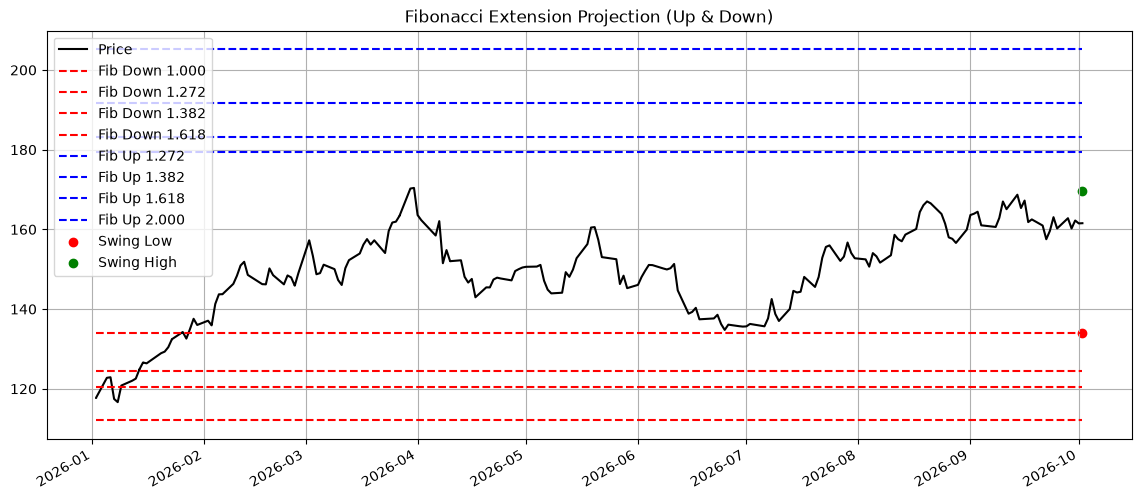

In [36]:
fib_result = fibonacci_extension.compute_fibonacci_extension(df.copy().reset_index())
fib_result

In [37]:
output_dir = Path("/workspace/data/figures/")
output_dir.mkdir(parents=True, exist_ok=True)
output_path = output_dir / f"{xom}_fibonacci_extension_{dt.datetime.now().strftime('%Y-%m-%d')}.png"
fib_result["plot_obj"].savefig(output_path, dpi=300, bbox_inches="tight")

#### 財務データ

In [38]:
response = request_api.update_corp_finance_data(
    code=xom,
    market=None
)
response

{'result': True}

In [39]:
xom_financials_data = request_api.get_corp_financials_data(code=xom, market=None)
xom_balance_sheet_data = request_api.get_corp_balance_sheet_data(code=xom, market=None)
xom_cash_flow_data = request_api.get_corp_cash_flow_data(code=xom, market=None)
xom_earnings_data = request_api.get_corp_earnings_data(code=xom, market=None)
xom_quarterly_earnings_data = request_api.get_corp_quarterly_earnings_data(code=xom, market=None)

In [40]:
# ４年分の財務データ
xom_financials_data_df = pd.DataFrame(xom_financials_data['results'])
# ４年分のバランスシート
xom_balance_sheet_data_df = pd.DataFrame(xom_balance_sheet_data['results'])
# ４年分のキャッシュフロー
xom_cash_flow_data_df = pd.DataFrame(xom_cash_flow_data['results'])
# ４年分の収益データ
xom_earnings_data_df = pd.DataFrame(xom_earnings_data['results'])
# ４年分の四半期収益データ
xom_quarterly_earnings_data_df = pd.DataFrame(xom_quarterly_earnings_data['results'])

In [41]:
"""
◆ 1. 株価・市場データ
• 現在株価（Price）
• 時価総額（Market Cap）
• 出来高（Volume）
• 52週高値・安値
• Beta（ボラティリティ指標）ß
"""
stock_prices_market_data.stock_prices_and_market_data(
    code=xom,
    market=None,
    bs_df=xom_balance_sheet_data_df
)

取得件数: 920
取得件数: 460
取得件数: 916
取得件数: 458
取得件数: 918
取得件数: 459
取得件数: 916
取得件数: 458


,close,market_cap,shares_outstanding,higher_rate_par_52_weeks,lower_rate_par_52_weeks,beta
0,50.178074,4.023780e+11,8.019000e+09,101.369899,43.723727,0.289339
1,73.025636,5.855926e+11,8.019000e+09,109.372220,65.569999,0.324243
2,99.111455,7.947841e+11,8.019095e+09,118.496943,87.340667,0.185749
3,98.384735,7.889472e+11,8.019000e+09,119.404671,93.309656,0.238965


In [ ]:
"""
◆ 2. 財務データ（Financials）+ EPS（Earnings Per Share）+ PBR（Price-to-Book Ratio）
• 売上高（Revenue）
• 営業利益（Operating Income）
• 純利益（Net Income）
• EBITDA（企業による）
• 総資産（Total Assets）
• 総負債（Total Liabilities）
• 現金（Cash）
• 希釈EPS（Diluted EPS）
• 基本EPS（Basic EPS）
• 営業キャッシュフロー（Operating Cash Flow）
• フリーキャッシュフロー（Free Cash Flow）
"""
financial_df = financial.calc_financial(
    code = xom,
    market = None,
)
financial_df.to_markdown()

取得件数: 13756


'|    | date                |       revenue |     earnings |   total_assets |   total_debt |   cash_and_cash_equivalents |      EBITDA |   operating_income |   basic_eps |   diluted_eps |   operating_cash_flow |   free_cash_flow |\n|---:|:--------------------|--------------:|-------------:|---------------:|-------------:|----------------------------:|------------:|-------------------:|------------:|--------------:|----------------------:|-----------------:|\n|  0 | 2021-12-31 00:00:00 | nan           | nan          |  nan           | nan          |                nan          | 0           |       nan          |      nan    |        nan    |          nan          |     nan          |\n|  1 | 2022-12-31 00:00:00 |   3.98675e+11 |   5.574e+10  |    3.69067e+11 |   4.1193e+10 |                  2.964e+10  | 1.02591e+11 |         6.4028e+10 |       13.26 |         13.26 |            7.6797e+10 |       5.839e+10  |\n|  2 | 2023-12-31 00:00:00 |   3.34697e+11 |   3.601e+10  |    3.76317e+11 

: 